# Supplementary figures

Built with the same plotting functions (`fig_panels.py`) and style (`pub_style.py`) as Figure 1.

**Supplementary Fig. 1 (accuracy)**: a, alignment bitscore to AF3-derived 3Di, ESM3Di vs ProstT5; b, distributions of 3Di identity to AF3-derived 3Di (dashed lines: medians); c, SCOPe superfamily- and fold-level sensitivity.

**Supplementary Fig. 2 (speed)**: a, ESM3Di runtime timed end to end (CLI, including model loading; filled markers) and inference only (model already loaded; open markers), with ProstT5 (end to end) as reference; b, runtime vs sequence length for the two language models (512 sequences per bin).

Data: `quality/results/3di_benchmark.csv`, `quality/results/scope_sensitivity.csv`, `speed/results/final_nseq.csv`, `speed/results/final_nseq_esm3di_cli.csv`, `speed/results/final_length_bins_plms.csv`. Output: `../figures/supplementary/`.

In [1]:
# Re-import fig_panels/pub_style when they change, without restarting the kernel
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from pub_style import MM, WIDTH_DOUBLE, add_aligned_panel_labels, save_pub, use_pub_style
from fig_panels import (
    BITSCORE_ARGS, MODEL_LABELS, label_line, plot_identity_density, plot_method_scatter,
    plot_runtime_vs_length, plot_scope_level, plot_esm3di_runtime_modes,
)

use_pub_style()
OUT_DIR = Path("../figures/supplementary")
# Same column width and row height as Figure 1, so panels have the same size
COLUMN_WIDTH = WIDTH_DOUBLE / 3
ROW_HEIGHT = 60 * MM

identity_df = pd.read_csv("quality/results/3di_benchmark.csv")
scope_df = pd.read_csv("quality/results/scope_sensitivity.csv")
nseq_df = pd.read_csv("speed/results/final_nseq.csv")
esm3di_cli_df = pd.read_csv("speed/results/final_nseq_esm3di_cli.csv")
length_plm_df = pd.read_csv("speed/results/final_length_bins_plms.csv")

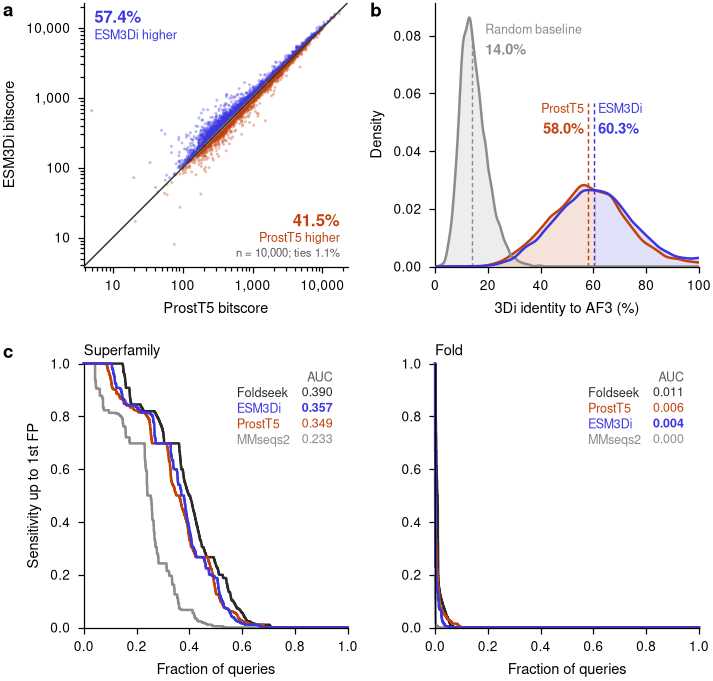

In [2]:
# Supplementary Fig. 1: a, bitscore scatter; b, identity distributions;
# c, SCOPe superfamily and fold (one panel, shared y label)
fig = plt.figure(figsize=(2 * COLUMN_WIDTH, 2 * ROW_HEIGHT), layout="constrained")
grid = fig.add_gridspec(2, 2)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_superfamily = fig.add_subplot(grid[1, 0])
ax_fold = fig.add_subplot(grid[1, 1])

plot_method_scatter(ax_a, identity_df, **BITSCORE_ARGS)
plot_identity_density(ax_b, identity_df)
ax_b.set_box_aspect(1)
plot_scope_level(ax_superfamily, scope_df, "Superfamily")
plot_scope_level(ax_fold, scope_df, "Fold", show_ylabel=False)
add_aligned_panel_labels(fig, {"a": ax_a, "b": ax_b, "c": [ax_superfamily, ax_fold]})

save_pub(fig, "supplementary_figure1", OUT_DIR)
plt.show()

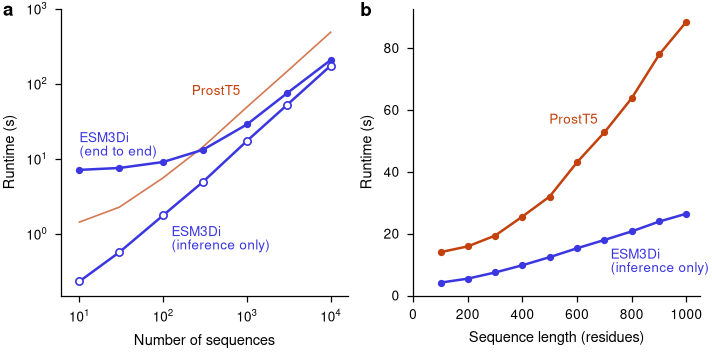

In [3]:
# Supplementary Fig. 2: a, ESM3Di runtime end to end and inference only (ProstT5 for reference);
# b, runtime vs sequence length (512 sequences per bin)
fig = plt.figure(figsize=(2 * COLUMN_WIDTH, ROW_HEIGHT), layout="constrained")
grid = fig.add_gridspec(1, 2)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])

plot_esm3di_runtime_modes(ax_a, nseq_df, esm3di_cli_df)
curves = plot_runtime_vs_length(ax_b, length_plm_df, ["esm3di", "prostt5"], log_y=False)
for model, dx, dy, ha, va in (("prostt5", -3, 3, "right", "bottom"), ("esm3di", 3, -3, "left", "top")):
    point = curves[model].iloc[6]
    # Panel a separates the ESM3Di timing modes, so name the one shown here
    text = "ESM3Di\n(inference only)" if model == "esm3di" else MODEL_LABELS[model]
    label_line(ax_b, point["seq_length"], point["mean"], text, model,
               dx=dx, dy=dy, ha=ha, va=va, linespacing=1.1)
add_aligned_panel_labels(fig, {"a": ax_a, "b": ax_b})

save_pub(fig, "supplementary_figure2", OUT_DIR)
plt.show()